In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
from sklearn.datasets import load_iris

iris_data = load_iris(as_frame=True)
df = iris_data.frame

df["species"] = df["target"].map(
    dict(enumerate(iris_data.target_names))
)

df = df.drop(columns=["target"])

print(df.head())
print("Dataset shape:", df.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
Dataset shape: (150, 5)


In [4]:
print(df.info())
print(df.describe())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nSpecies counts:")
print(df["species"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000      

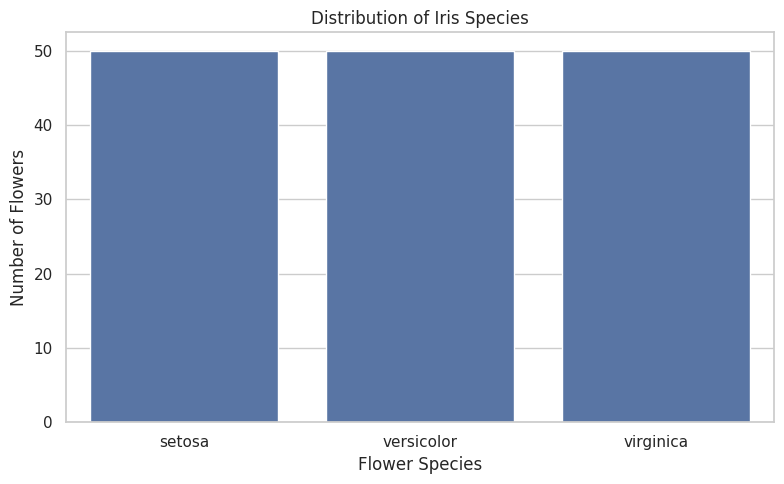

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Flowers")
plt.tight_layout()
plt.show()

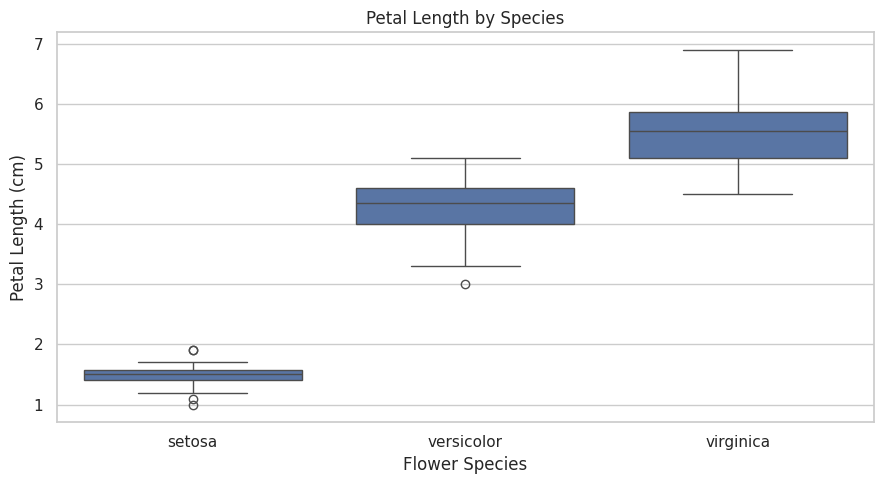

In [6]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="species", y="petal length (cm)")
plt.title("Petal Length by Species")
plt.xlabel("Flower Species")
plt.ylabel("Petal Length (cm)")
plt.tight_layout()
plt.show()

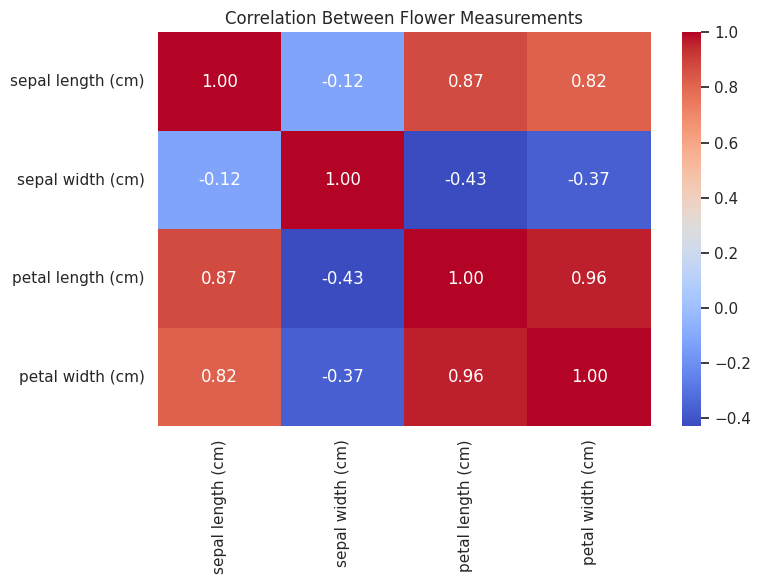

In [7]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Flower Measurements")
plt.tight_layout()
plt.show()

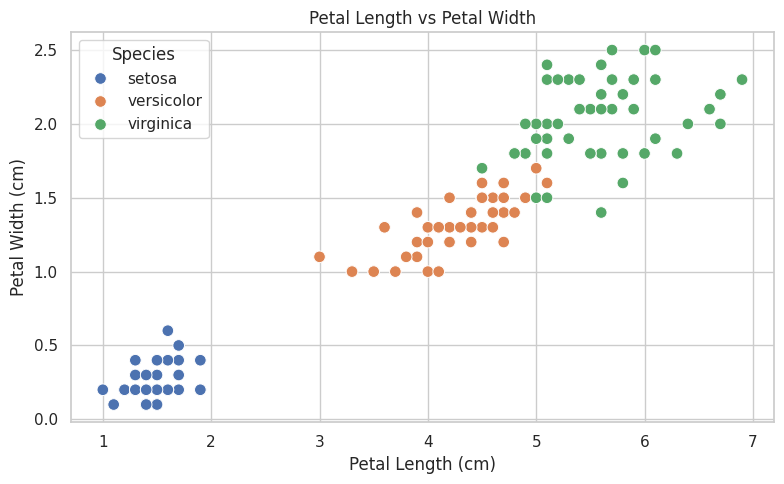

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=70
)
plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

In [9]:
print("Missing values before cleaning:")
print(df.isnull().sum())

df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))

print("\nAverage measurements by species:")
print(
    df_clean.groupby("species")
    .mean(numeric_only=True)
    .round(2)
)

Missing values before cleaning:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Original rows: 150
Rows after removing duplicates: 149

Average measurements by species:
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                   5.01              3.43               1.46   
versicolor               5.94              2.77               4.26   
virginica                6.60              2.98               5.56   

            petal width (cm)  
species                       
setosa                  0.25  
versicolor              1.33  
virginica               2.03  
